<a href="https://colab.research.google.com/github/tahzibultamim/PythonProjects/blob/sM/iee_ensemble_shap_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import drive

# Added force_remount=True to resolve stale mounting issues
drive.mount('/content/drive', force_remount=True)

print("Google Drive connected successfully!")

Mounted at /content/drive
Google Drive connected successfully!


In [7]:
!pip install -q shap xgboost

In [8]:

# ==========================================
# CELL 1: INSTALL ALL REQUIRED PACKAGES
# ==========================================

%pip install -q numpy pandas matplotlib seaborn scikit-learn xgboost shap joblib

print("All research packages installed successfully!")


All research packages installed successfully!


In [9]:
# ==========================================
# CELL 2: IMPORT LIBRARIES
# ==========================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import xgboost
import sklearn
import joblib

from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, VarianceThreshold

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from xgboost import XGBClassifier

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    confusion_matrix
)

warnings.filterwarnings("ignore")

SEED = 42

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("SHAP:", shap.__version__)

print("\nAll libraries imported successfully!")

NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
XGBoost: 3.4.1
SHAP: 0.54.1

All libraries imported successfully!


In [10]:
# ==========================================
# CELL 4: LOAD TCGA-THCA DATASET
# ==========================================
import os
from pathlib import Path
import pandas as pd

# The file was found in the 'datasets' (plural) folder in Google Drive
DATA_PATH = "/content/drive/MyDrive/datasets/TCGA_THCA_FINAL_DATASET.csv"
RESULTS_DIR = Path("/content/drive/MyDrive/datasets/TCGA_THCA_Research_Results")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        f"Please verify the path or the folder structure in your Google Drive."
    )

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (517, 19967)


,sample_submitter_id,file_id,patient_id,sample_type,label,ENSG00000000003.15__TSPAN6,ENSG00000000005.6__TNMD,ENSG00000000419.13__DPM1,ENSG00000000457.14__SCYL3,ENSG00000000460.17__C1orf112,...,ENSG00000288649.1__ACTL10,ENSG00000288654.1__AC119733.1,ENSG00000288656.1__AC020765.6,ENSG00000288658.1__AC010980.1,ENSG00000288660.1__AC004233.4,ENSG00000288661.1__AL451106.1,ENSG00000288669.1__AC008763.4,ENSG00000288671.1__AC006486.3,ENSG00000288674.1__AL391628.1,ENSG00000288675.1__AP006621.6
0,TCGA-4C-A93U-01A,d7082abc-9812-4d52-a61f-3d0c005e5ade,TCGA-4C-A93U,Primary Tumor,1,5.64094,0.685088,6.18679,2.79967,1.87468,...,0,0,0.00000,0.264957,0.000000,0,0.0,0,0.097476,0.848798
1,TCGA-BJ-A0Z3-01A,b78a76b0-0be6-4f47-ae53-7b4a6b339888,TCGA-BJ-A0Z3,Primary Tumor,1,5.74985,0.000000,6.29341,3.18552,1.80876,...,0,0,0.00000,0.175301,0.233520,0,0.0,0,0.080658,1.097950
2,TCGA-BJ-A0ZC-01A,07c4db33-2a66-40be-b5fb-3c9b3271b874,TCGA-BJ-A0ZC,Primary Tumor,1,5.39993,0.267596,6.34008,3.50024,1.22373,...,0,0,0.00000,3.053270,0.000000,0,0.0,0,0.022332,0.488412
3,TCGA-BJ-A18Y-01A,4b73aa55-1b96-4d6a-afef-fae80dc44ffe,TCGA-BJ-A18Y,Primary Tumor,1,5.35339,0.128293,6.50881,3.34527,1.37095,...,0,0,0.04991,1.463570,0.000000,0,0.0,0,0.080112,1.015280
4,TCGA-BJ-A18Z-01A,d3572a69-92b7-4696-8894-d52ababe370d,TCGA-BJ-A18Z,Primary Tumor,1,5.42082,0.000000,6.17039,2.89569,1.64902,...,0,0,0.00000,0.483880,0.158596,0,0.0,0,0.061983,1.237200


In [11]:

# ==========================================
# CELL 5: DATA QUALITY CHECK
# ==========================================

metadata_cols = [
    "sample_submitter_id",
    "file_id",
    "patient_id",
    "sample_type",
    "label"
]

required = metadata_cols

missing_columns = [
    col for col in required if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

gene_cols = [
    col for col in df.columns
    if col not in metadata_cols
]

X = df[gene_cols].apply(
    pd.to_numeric,
    errors="coerce"
).astype(np.float32)

y = df["label"].astype(int)

groups = df["patient_id"].astype(str)

expected_labels = df["sample_type"].map({
    "Primary Tumor": 1,
    "Solid Tissue Normal": 0
})

assert expected_labels.notna().all()
assert np.array_equal(
    expected_labels.to_numpy(),
    y.to_numpy()
)

assert df["patient_id"].notna().all()
assert df["sample_submitter_id"].is_unique
assert X.isna().sum().sum() == 0
assert np.isfinite(X.to_numpy()).all()

print("Samples:", X.shape[0])
print("Genes:", X.shape[1])
print("Unique patients:", groups.nunique())

print("\nSample distribution:")
print(df["sample_type"].value_counts())

print("\nClass distribution:")
print(y.value_counts())

print("\nMissing values:", X.isna().sum().sum())
print("Infinite values:", np.isinf(X.to_numpy()).sum())

print("\nDATA QUALITY VERIFIED!")


Samples: 517
Genes: 19962
Unique patients: 462

Sample distribution:
sample_type
Primary Tumor          458
Solid Tissue Normal     59
Name: count, dtype: int64

Class distribution:
label
1    458
0     59
Name: count, dtype: int64

Missing values: 0
Infinite values: 0

DATA QUALITY VERIFIED!


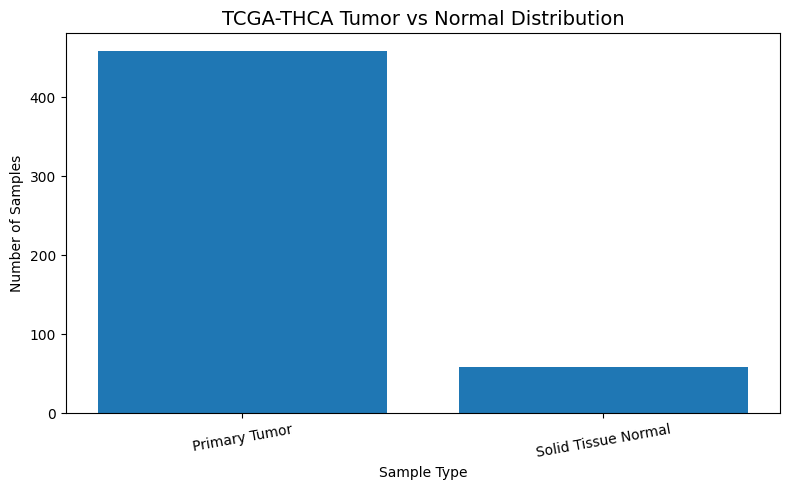

In [12]:
# ==========================================
# SAMPLE DISTRIBUTION PLOT
# ==========================================

sample_order = ["Primary Tumor", "Solid Tissue Normal"]
sample_counts = (
    df["sample_type"]
    .value_counts()
    .reindex(sample_order, fill_value=0)
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    sample_counts.index,
    sample_counts.values
)

ax.set_title(
    "TCGA-THCA Tumor vs Normal Distribution",
    fontsize=14
)
ax.set_xlabel("Sample Type")
ax.set_ylabel("Number of Samples")
ax.tick_params(axis="x", rotation=10)

fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "01_sample_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

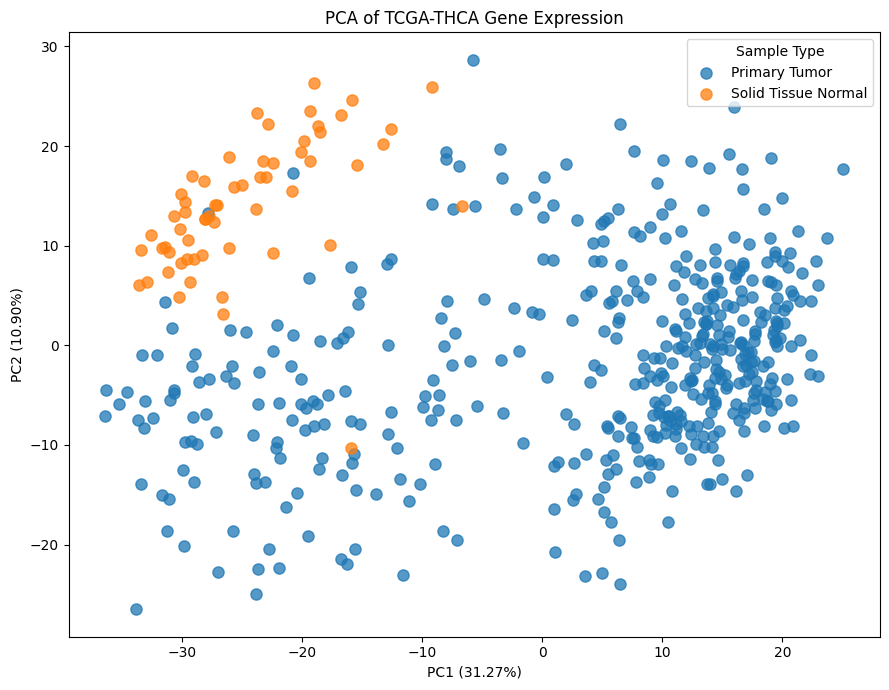

In [13]:
# ==========================================
# PCA VISUALIZATION
# ==========================================

from sklearn.decomposition import PCA

# Select the 1000 most variable genes for visualization.
gene_variance = X.var(axis=0)
top_genes = gene_variance.nlargest(min(1000, X.shape[1])).index
X_pca = X[top_genes]

# Standardization for visualization.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca)

# PCA.
pca = PCA(n_components=2, random_state=SEED)
coordinates = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    coordinates,
    columns=["PC1", "PC2"]
)
pca_df["Sample_Type"] = df["sample_type"].values

# Plot each sample type separately for consistent legend handling.
fig, ax = plt.subplots(figsize=(9, 7))

for sample_type in ["Primary Tumor", "Solid Tissue Normal"]:
    mask = pca_df["Sample_Type"].eq(sample_type).to_numpy()
    ax.scatter(
        pca_df.loc[mask, "PC1"],
        pca_df.loc[mask, "PC2"],
        s=65,
        alpha=0.75,
        label=sample_type
    )

ax.set_title("PCA of TCGA-THCA Gene Expression")
ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}%)"
)
ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)"
)
ax.legend(title="Sample Type")

fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "02_PCA_plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [14]:
# ==========================================
# CELL 8: FEATURE SELECTION + BASE / ENSEMBLE MODELS
# ==========================================

K_FEATURES = 500

def create_pipeline(model, scale=False):
    """
    Feature selection is fitted inside each training fold.
    This prevents feature-selection leakage into validation folds.
    """
    steps = [
        ("variance", VarianceThreshold()),
        ("select", SelectKBest(
            score_func=f_classif,
            k=K_FEATURES
        ))
    ]

    if scale:
        steps.append(("scaler", StandardScaler()))

    steps.append(("model", model))
    return Pipeline(steps)


class GroupAwareStackingClassifier(ClassifierMixin, BaseEstimator):
    """
    Stacking classifier with patient-group-aware out-of-fold predictions.

    Standard StackingClassifier does not pass groups to its internal
    cross-validation. This implementation explicitly uses
    StratifiedGroupKFold for the meta-feature generation stage.

    Base estimators must be sklearn Pipelines whose final step is named
    'model' and whose classifiers support sample_weight.
    """

    def __init__(
        self,
        estimators,
        final_estimator=None,
        n_splits=3,
        random_state=42
    ):
        self.estimators = estimators
        self.final_estimator = final_estimator
        self.n_splits = n_splits
        self.random_state = random_state

    @staticmethod
    def _fit_weighted_pipeline(estimator, X_fit, y_fit):
        fitted = clone(estimator)

        if not isinstance(fitted, Pipeline) or "model" not in fitted.named_steps:
            raise TypeError(
                "Each stacking base estimator must be a Pipeline "
                "with its final classifier named 'model'."
            )

        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=np.asarray(y_fit)
        )

        fitted.fit(
            X_fit,
            y_fit,
            model__sample_weight=sample_weights
        )
        return fitted

    @staticmethod
    def _positive_probability(estimator, X_eval):
        probabilities = estimator.predict_proba(X_eval)
        classes = np.asarray(estimator.classes_)
        positive_index = np.flatnonzero(classes == 1)

        if len(positive_index) != 1:
            raise ValueError(
                "A stacking base estimator must expose class 1 "
                "in predict_proba()."
            )

        return probabilities[:, positive_index[0]]

    def fit(self, X, y, groups=None):
        if groups is None:
            raise ValueError(
                "Patient groups are required for Group-Aware Stacking."
            )

        y_array = np.asarray(y)
        groups_array = np.asarray(groups)

        if len(X) != len(y_array) or len(y_array) != len(groups_array):
            raise ValueError("X, y, and groups must have equal lengths.")

        if set(np.unique(y_array)) != {0, 1}:
            raise ValueError(
                "Group-Aware Stacking expects binary labels encoded as 0 and 1."
            )

        n_unique_groups = pd.Series(groups_array).nunique()
        actual_splits = min(int(self.n_splits), int(n_unique_groups))

        if actual_splits < 2:
            raise ValueError(
                "At least two unique patient groups are required for stacking."
            )

        inner_cv = StratifiedGroupKFold(
            n_splits=actual_splits,
            shuffle=True,
            random_state=self.random_state
        )

        oof_features = np.full(
            (len(y_array), len(self.estimators)),
            np.nan,
            dtype=np.float64
        )

        # Generate out-of-fold meta-features without splitting patients
        # across the inner training and validation sets.
        for inner_fold, (inner_train_idx, inner_valid_idx) in enumerate(
            inner_cv.split(X, y_array, groups_array), 1
        ):
            y_inner_train = y_array[inner_train_idx]

            if np.unique(y_inner_train).size != 2:
                raise ValueError(
                    f"Inner stacking fold {inner_fold} has only one "
                    "class in its training partition."
                )

            X_inner_train = X.iloc[inner_train_idx]
            X_inner_valid = X.iloc[inner_valid_idx]

            for estimator_index, (estimator_name, estimator) in enumerate(
                self.estimators
            ):
                fitted_base = self._fit_weighted_pipeline(
                    estimator,
                    X_inner_train,
                    y_inner_train
                )

                oof_features[inner_valid_idx, estimator_index] = (
                    self._positive_probability(
                        fitted_base,
                        X_inner_valid
                    )
                )

        if not np.isfinite(oof_features).all():
            raise RuntimeError(
                "Stacking meta-features contain missing or non-finite values."
            )

        # Train the meta-classifier only on group-safe OOF predictions.
        if self.final_estimator is None:
            meta_estimator = LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=self.random_state
            )
        else:
            meta_estimator = clone(self.final_estimator)

        meta_estimator.fit(oof_features, y_array)

        # Refit each base learner on the complete outer-training partition.
        fitted_estimators = []
        for estimator_name, estimator in self.estimators:
            fitted_base = self._fit_weighted_pipeline(
                estimator,
                X,
                y_array
            )
            fitted_estimators.append((estimator_name, fitted_base))

        self.estimators_ = fitted_estimators
        self.final_estimator_ = meta_estimator
        self.classes_ = np.asarray(meta_estimator.classes_)
        self.n_features_in_ = X.shape[1]

        return self

    def _meta_features(self, X):
        return np.column_stack([
            self._positive_probability(estimator, X)
            for _, estimator in self.estimators_
        ])

    def predict_proba(self, X):
        meta_features = self._meta_features(X)
        return self.final_estimator_.predict_proba(meta_features)

    def predict(self, X):
        meta_features = self._meta_features(X)
        return self.final_estimator_.predict(meta_features)


# ------------------------------
# ORIGINAL SEVEN MODELS
# ------------------------------

models = {
    "Logistic Regression": create_pipeline(
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=SEED
        ),
        scale=True
    ),

    "Decision Tree": create_pipeline(
        DecisionTreeClassifier(
            max_depth=4,
            class_weight="balanced",
            random_state=SEED
        )
    ),

    "Random Forest": create_pipeline(
        RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced_subsample",
            random_state=SEED,
            n_jobs=-1
        )
    ),

    "Gradient Boosting": create_pipeline(
        GradientBoostingClassifier(
            random_state=SEED
        )
    ),

    "XGBoost": create_pipeline(
        XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=SEED,
            n_jobs=-1
        )
    ),

    "SVM": create_pipeline(
        SVC(
            probability=False,
            class_weight="balanced",
            random_state=SEED
        ),
        scale=True
    ),

    "KNN": create_pipeline(
        KNeighborsClassifier(
            n_neighbors=5,
            weights="distance"
        ),
        scale=True
    )
}


# ------------------------------
#  ENSEMBLE MODELS
# ------------------------------

# 1. Extra Trees: randomized tree ensemble
models["Extra Trees"] = create_pipeline(
    ExtraTreesClassifier(
        n_estimators=250,
        class_weight="balanced_subsample",
        random_state=SEED,
        n_jobs=-1
    )
)

# 2. AdaBoost: adaptive boosting with a shallow decision-tree learner
models["AdaBoost"] = create_pipeline(
    AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=1,
            class_weight="balanced",
            random_state=SEED
        ),
        n_estimators=150,
        learning_rate=0.5,
        random_state=SEED
    )
)

# 3. Soft Voting: combines calibrated class-probability outputs.
# Each constituent pipeline performs its own fold-specific feature selection.
models["Soft Voting Ensemble"] = VotingClassifier(
    estimators=[
        ("lr", clone(models["Logistic Regression"])),
        ("rf", clone(models["Random Forest"])),
        ("extra_trees", clone(models["Extra Trees"]))
    ],
    voting="soft",
    weights=[1, 2, 2],
    n_jobs=1
)

# 4. Group-aware Stacking:
# Two base learners generate out-of-fold probabilities using patient groups.
stack_base_estimators = [
    (
        "random_forest",
        create_pipeline(
            RandomForestClassifier(
                n_estimators=150,
                class_weight="balanced_subsample",
                random_state=SEED,
                n_jobs=-1
            )
        )
    ),
    (
        "xgboost",
        create_pipeline(
            XGBClassifier(
                n_estimators=150,
                max_depth=3,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="binary:logistic",
                eval_metric="logloss",
                tree_method="hist",
                random_state=SEED,
                n_jobs=-1
            )
        )
    )
]

models["Group-Aware Stacking Ensemble"] = GroupAwareStackingClassifier(
    estimators=stack_base_estimators,
    final_estimator=LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=SEED
    ),
    n_splits=3,
    random_state=SEED
)

print("Total models:", len(models))
print("\nModel list:")
for model_number, model_name in enumerate(models, 1):
    print(f"{model_number:02d}. {model_name}")

print("\nOriginal models retained: 7")
print("New ensemble approaches added: 4")

Total models: 11

Model list:
01. Logistic Regression
02. Decision Tree
03. Random Forest
04. Gradient Boosting
05. XGBoost
06. SVM
07. KNN
08. Extra Trees
09. AdaBoost
10. Soft Voting Ensemble
11. Group-Aware Stacking Ensemble

Original models retained: 7
New ensemble approaches added: 4


In [15]:

# ==========================================
# CELL 9: STRATIFIED GROUP CROSS-VALIDATION
# ==========================================

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

splits = list(
    cv.split(X, y, groups)
)

for fold, (train_idx, test_idx) in enumerate(
    splits, 1
):

    train_patients = set(groups.iloc[train_idx])
    test_patients = set(groups.iloc[test_idx])

    assert train_patients.isdisjoint(
        test_patients
    )

    print(f"\nFOLD {fold}")

    print("Training samples:", len(train_idx))
    print("Validation samples:", len(test_idx))

    print(
        "Training labels:",
        y.iloc[train_idx].value_counts().to_dict()
    )

    print(
        "Validation labels:",
        y.iloc[test_idx].value_counts().to_dict()
    )

    if y.iloc[test_idx].nunique() != 2:
        raise ValueError(
            f"Fold {fold} does not contain both classes."
        )

print("\nPatient-level cross-validation verified!")



FOLD 1
Training samples: 413
Validation samples: 104
Training labels: {1: 366, 0: 47}
Validation labels: {1: 92, 0: 12}

FOLD 2
Training samples: 414
Validation samples: 103
Training labels: {1: 366, 0: 48}
Validation labels: {1: 92, 0: 11}

FOLD 3
Training samples: 414
Validation samples: 103
Training labels: {1: 367, 0: 47}
Validation labels: {1: 91, 0: 12}

FOLD 4
Training samples: 412
Validation samples: 105
Training labels: {1: 366, 0: 46}
Validation labels: {1: 92, 0: 13}

FOLD 5
Training samples: 415
Validation samples: 102
Training labels: {1: 367, 0: 48}
Validation labels: {1: 91, 0: 11}

Patient-level cross-validation verified!


In [16]:
# ==========================================
# CELL 10: TRAIN AND EVALUATE ALL 11 MODELS
# ==========================================

results = []

WEIGHTED_PIPELINE_MODELS = {
    "Gradient Boosting",
    "XGBoost",
    "AdaBoost"
}

for model_name, model in models.items():

    print("\n================================")
    print("TRAINING:", model_name)
    print("================================")

    for fold, (train_idx, test_idx) in enumerate(splits, 1):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        groups_train = groups.iloc[train_idx]

        fitted_model = clone(model)

        # Group-aware stacking receives patient IDs and creates its own
        # group-safe inner out-of-fold predictions.
        if model_name == "Group-Aware Stacking Ensemble":
            fitted_model.fit(
                X_train,
                y_train,
                groups=groups_train
            )

        # Class-weighted training for the original boosting pipelines.
        elif model_name in WEIGHTED_PIPELINE_MODELS:
            weights = compute_sample_weight(
                class_weight="balanced",
                y=y_train
            )

            fitted_model.fit(
                X_train,
                y_train,
                model__sample_weight=weights
            )

        else:
            fitted_model.fit(X_train, y_train)

        # Predictions
        predictions = fitted_model.predict(X_test)

        # Ranking scores for ROC-AUC and PR-AUC.
        if callable(getattr(fitted_model, "predict_proba", None)):
            probabilities = fitted_model.predict_proba(X_test)
            model_classes = np.asarray(fitted_model.classes_)
            positive_index = np.flatnonzero(model_classes == 1)

            if len(positive_index) != 1:
                raise ValueError(
                    f"{model_name} did not return a probability column for class 1."
                )

            positive_scores = probabilities[:, positive_index[0]]
            negative_scores = 1 - positive_scores

        elif callable(getattr(fitted_model, "decision_function", None)):
            positive_scores = fitted_model.decision_function(X_test)
            negative_scores = -positive_scores

        else:
            # Fallback for classifiers that expose only hard predictions.
            positive_scores = np.asarray(predictions, dtype=float)
            negative_scores = 1 - positive_scores

        # Confusion matrix
        tn, fp, fn, tp = confusion_matrix(
            y_test,
            predictions,
            labels=[0, 1]
        ).ravel()

        sensitivity = tp / (tp + fn) if (tp + fn) else 0
        specificity = tn / (tn + fp) if (tn + fp) else 0

        # Metrics
        fold_result = {
            "Model": model_name,
            "Fold": fold,

            "Accuracy": accuracy_score(y_test, predictions),

            "Balanced_Accuracy": balanced_accuracy_score(
                y_test,
                predictions
            ),

            "Precision_Tumor": precision_score(
                y_test,
                predictions,
                zero_division=0
            ),

            "Sensitivity_Tumor": sensitivity,

            "Specificity_Normal": specificity,

            "F1_Tumor": f1_score(
                y_test,
                predictions,
                zero_division=0
            ),

            "ROC_AUC": roc_auc_score(
                y_test,
                positive_scores
            ),

            "PR_AUC_Tumor": average_precision_score(
                y_test,
                positive_scores
            ),

            "PR_AUC_Normal": average_precision_score(
                1 - y_test,
                negative_scores
            ),

            "MCC": matthews_corrcoef(
                y_test,
                predictions
            )
        }

        results.append(fold_result)

        print(
            f"Fold {fold}: "
            f"ROC-AUC={fold_result['ROC_AUC']:.4f}, "
            f"MCC={fold_result['MCC']:.4f}"
        )

    print("Completed:", model_name)

results_df = pd.DataFrame(results)

expected_result_rows = len(models) * len(splits)
if len(results_df) != expected_result_rows:
    raise RuntimeError(
        f"Expected {expected_result_rows} fold results, "
        f"but obtained {len(results_df)}."
    )

print("\nALL MODELS COMPLETED!")
print("Models evaluated:", results_df["Model"].nunique())
print("Total fold-level evaluations:", len(results_df))

display(results_df.head())


TRAINING: Logistic Regression
Fold 1: ROC-AUC=0.9683, MCC=0.8275
Fold 2: ROC-AUC=1.0000, MCC=0.9098
Fold 3: ROC-AUC=0.9945, MCC=0.9156
Fold 4: ROC-AUC=1.0000, MCC=1.0000
Fold 5: ROC-AUC=1.0000, MCC=0.9097
Completed: Logistic Regression

TRAINING: Decision Tree
Fold 1: ROC-AUC=0.9167, MCC=0.9031
Fold 2: ROC-AUC=0.9946, MCC=0.9522
Fold 3: ROC-AUC=0.9167, MCC=0.9030
Fold 4: ROC-AUC=0.9231, MCC=0.9100
Fold 5: ROC-AUC=0.8926, MCC=0.7560
Completed: Decision Tree

TRAINING: Random Forest
Fold 1: ROC-AUC=0.9792, MCC=0.9058
Fold 2: ROC-AUC=1.0000, MCC=0.9522
Fold 3: ROC-AUC=1.0000, MCC=0.9522
Fold 4: ROC-AUC=1.0000, MCC=0.8631
Fold 5: ROC-AUC=1.0000, MCC=1.0000
Completed: Random Forest

TRAINING: Gradient Boosting
Fold 1: ROC-AUC=0.9529, MCC=0.9058
Fold 2: ROC-AUC=0.9926, MCC=0.9522
Fold 3: ROC-AUC=0.9973, MCC=0.9522
Fold 4: ROC-AUC=0.9615, MCC=0.9100
Fold 5: ROC-AUC=0.8242, MCC=0.8420
Completed: Gradient Boosting

TRAINING: XGBoost
Fold 1: ROC-AUC=0.9828, MCC=0.8645
Fold 2: ROC-AUC=1.0000, MC

,Model,Fold,Accuracy,Balanced_Accuracy,Precision_Tumor,Sensitivity_Tumor,Specificity_Normal,F1_Tumor,ROC_AUC,PR_AUC_Tumor,PR_AUC_Normal,MCC
0,Logistic Regression,1,0.961538,0.942029,0.988889,0.967391,0.916667,0.978022,0.968297,0.995574,0.810093,0.827523
1,Logistic Regression,2,0.980583,0.989130,1.000000,0.978261,1.000000,0.989011,1.000000,1.000000,1.000000,0.909813
2,Logistic Regression,3,0.980583,0.989011,1.000000,0.978022,1.000000,0.988889,0.994505,0.999298,0.959366,0.915590
3,Logistic Regression,4,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
4,Logistic Regression,5,0.980392,0.989011,1.000000,0.978022,1.000000,0.988889,1.000000,1.000000,1.000000,0.909702


In [17]:
# ==========================================
# CELL 11: ALL-MODEL PERFORMANCE SUMMARY
# ==========================================

metric_columns = [
    "Accuracy",
    "Balanced_Accuracy",
    "Precision_Tumor",
    "Sensitivity_Tumor",
    "Specificity_Normal",
    "F1_Tumor",
    "ROC_AUC",
    "PR_AUC_Tumor",
    "PR_AUC_Normal",
    "MCC"
]

summary = results_df.groupby("Model")[
    metric_columns
].agg(["mean", "std"])

summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in summary.columns
]

summary = summary.sort_values(
    "MCC_mean",
    ascending=False
)

display(summary.round(4))

# Save all original and ensemble model results.
results_df.to_csv(
    RESULTS_DIR / "All_Model_Fold_Results.csv",
    index=False
)

summary.to_csv(
    RESULTS_DIR / "All_Model_Performance_Summary.csv"
)

print("All-model performance results saved!")

,Accuracy_mean,Accuracy_std,Balanced_Accuracy_mean,Balanced_Accuracy_std,Precision_Tumor_mean,Precision_Tumor_std,Sensitivity_Tumor_mean,Sensitivity_Tumor_std,Specificity_Normal_mean,Specificity_Normal_std,F1_Tumor_mean,F1_Tumor_std,ROC_AUC_mean,ROC_AUC_std,PR_AUC_Tumor_mean,PR_AUC_Tumor_std,PR_AUC_Normal_mean,PR_AUC_Normal_std,MCC_mean,MCC_std
Model,,,,,,,,,,,,,,,,,,,,
Group-Aware Stacking Ensemble,0.9884,0.0105,0.9724,0.0234,0.9935,0.0060,0.9935,0.0097,0.9513,0.0446,0.9935,0.0060,0.9966,0.0077,0.9995,0.0011,0.9886,0.0255,0.9449,0.0493
XGBoost,0.9884,0.0105,0.9724,0.0234,0.9935,0.0060,0.9935,0.0097,0.9513,0.0446,0.9935,0.0060,0.9966,0.0077,0.9995,0.0011,0.9877,0.0276,0.9449,0.0493
KNN,0.9865,0.0086,0.9719,0.0329,0.9936,0.0095,0.9913,0.0092,0.9526,0.0696,0.9924,0.0049,0.9735,0.0354,0.9930,0.0096,0.9237,0.0753,0.9355,0.0407
Random Forest,0.9866,0.0109,0.9581,0.0461,0.9893,0.0129,0.9957,0.0060,0.9205,0.0943,0.9924,0.0061,0.9958,0.0093,0.9994,0.0014,0.9846,0.0343,0.9347,0.0521
Extra Trees,0.9865,0.0051,0.9647,0.0304,0.9914,0.0089,0.9935,0.0060,0.9359,0.0652,0.9924,0.0029,0.9955,0.0101,0.9994,0.0015,0.9787,0.0476,0.9345,0.0243
AdaBoost,0.9846,0.0129,0.9702,0.0234,0.9935,0.0060,0.9891,0.0133,0.9513,0.0446,0.9912,0.0074,0.9978,0.0049,0.9997,0.0007,0.9895,0.0234,0.9279,0.0562
SVM,0.9826,0.0143,0.9697,0.0348,0.9935,0.0096,0.9869,0.0142,0.9526,0.0696,0.9901,0.0082,0.9949,0.0108,0.9993,0.0015,0.9707,0.0624,0.9199,0.0636
Soft Voting Ensemble,0.9826,0.0080,0.9625,0.0297,0.9914,0.0089,0.9891,0.0109,0.9359,0.0652,0.9902,0.0046,0.9955,0.0101,0.9994,0.0014,0.9811,0.0423,0.9177,0.0365
Logistic Regression,0.9806,0.0136,0.9818,0.0228,0.9978,0.0050,0.9803,0.0119,0.9833,0.0373,0.9890,0.0078,0.9926,0.0138,0.9990,0.0019,0.9539,0.0823,0.9125,0.0610


All-model performance results saved!


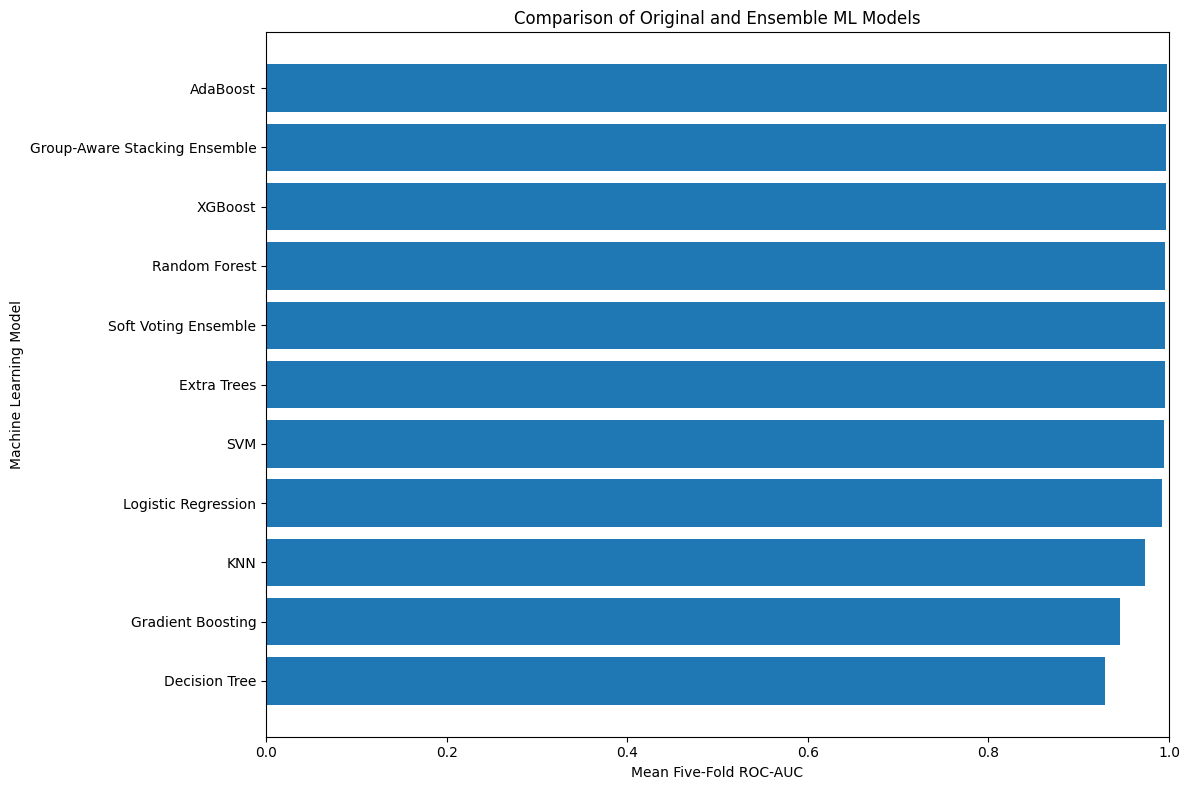

Best model by mean MCC: Group-Aware Stacking Ensemble
Best mean MCC: 0.9449


In [18]:

# ==========================================
# CELL 12: COMPARISON OF ALL MODELS
# ==========================================

plot_df = (
    results_df.groupby("Model")["ROC_AUC"]
    .mean()
    .sort_values(ascending=True)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(
    plot_df["Model"],
    plot_df["ROC_AUC"]
)

ax.set_title("Comparison of Original and Ensemble ML Models")
ax.set_xlabel("Mean Five-Fold ROC-AUC")
ax.set_ylabel("Machine Learning Model")
ax.set_xlim(0, 1)

fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "03_All_Model_Comparison_ROC_AUC.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Best model by mean MCC:", summary.index[0])
print("Best mean MCC:", round(summary.iloc[0]["MCC_mean"], 4))


## Final Stage — SHAP Explainability

SHAP is intentionally placed **after every original and ensemble model has been trained and compared**. The notebook selects the best eligible tree-based model by mean five-fold MCC and explains its predictions on the held-out samples from Fold 1.

**Important interpretation note:** Soft Voting and Group-Aware Stacking are included in the model comparison. The TreeExplainer analysis below is applied to the best individual tree-based model because TreeExplainer is designed for supported tree estimators, not an arbitrary combination of multiple fitted pipelines. This preserves the original notebook's SHAP approach while keeping the ensemble evaluation separate and transparent.

The Stacking ensemble uses patient-group-aware inner folds to generate out-of-fold meta-features, preventing patient overlap between its inner training and validation partitions.

In [19]:
# ==========================================
# SHAP ANALYSIS: SELECT THE BEST TREE-BASED MODEL
# ==========================================

print("SHAP version:", shap.__version__)

# TreeExplainer-compatible tree-based candidates.
# Voting and stacking are evaluated above, but are not passed directly
# to TreeExplainer because they combine multiple separately fitted models.
tree_models = [
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting",
    "XGBoost",
    "Extra Trees"
]

available_tree_models = [
    name for name in tree_models
    if name in summary.index
]

if not available_tree_models:
    raise RuntimeError(
        "No eligible tree-based model is available for SHAP analysis."
    )

best_tree_model = summary.loc[
    available_tree_models,
    "MCC_mean"
].idxmax()

print("Best tree-based model for SHAP:", best_tree_model)
print(
    "Mean five-fold MCC:",
    round(summary.loc[best_tree_model, "MCC_mean"], 4)
)
print(
    "\nNote: SHAP will explain this model on Fold 1 held-out samples, "
    "preserving the original notebook's validation design."
)

SHAP version: 0.54.1
Best tree-based model for SHAP: XGBoost
Mean five-fold MCC: 0.9449

Note: SHAP will explain this model on Fold 1 held-out samples, preserving the original notebook's validation design.


In [20]:
# ==========================================
# SHAP: TRAIN THE SELECTED TREE MODEL ON FOLD 1
# ==========================================

train_idx, test_idx = splits[0]

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

shap_model = clone(models[best_tree_model])

if best_tree_model in {
    "Gradient Boosting",
    "XGBoost",
    "AdaBoost"
}:
    weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train
    )

    shap_model.fit(
        X_train,
        y_train,
        model__sample_weight=weights
    )
else:
    shap_model.fit(X_train, y_train)

print("SHAP model trained successfully!")
print("Selected model:", best_tree_model)
print("Training samples:", len(train_idx))
print("Held-out samples:", len(test_idx))
print("Training patients:", groups.iloc[train_idx].nunique())
print("Held-out patients:", groups.iloc[test_idx].nunique())

assert set(groups.iloc[train_idx]).isdisjoint(
    set(groups.iloc[test_idx])
), "Patient leakage detected in the SHAP train/test split!"

SHAP model trained successfully!
Selected model: XGBoost
Training samples: 413
Held-out samples: 104
Training patients: 369
Held-out patients: 93


In [21]:

# ==========================================
# CELL 14: EXTRACT SELECTED GENES
# ==========================================

# Apply fitted preprocessing to held-out data
X_test_transformed = shap_model[:-1].transform(
    X_test
)

# Recover the original gene names
variance_mask = (
    shap_model.named_steps["variance"]
    .get_support()
)

genes_after_variance = X.columns[
    variance_mask
]

selection_mask = (
    shap_model.named_steps["select"]
    .get_support()
)

selected_gene_names = genes_after_variance[
    selection_mask
]

X_test_selected = pd.DataFrame(
    X_test_transformed,
    columns=selected_gene_names
)

print(
    "Selected genes:",
    len(selected_gene_names)
)

print(
    "SHAP input shape:",
    X_test_selected.shape
)

display(
    X_test_selected.iloc[:5, :10]
)


Selected genes: 500
SHAP input shape: (104, 500)


,ENSG00000003436.16__TFPI,ENSG00000004399.13__PLXND1,ENSG00000004776.13__HSPB6,ENSG00000006625.18__GGCT,ENSG00000007062.12__PROM1,ENSG00000008256.16__CYTH3,ENSG00000008277.14__ADAM22,ENSG00000009694.13__TENM1,ENSG00000012223.13__LTF,ENSG00000015475.19__BID
0,2.350550,6.16224,1.977870,6.64343,0.531469,5.00117,1.089090,3.217340,6.51582,5.26943
1,0.714136,5.95462,0.231555,4.44975,0.264476,5.30182,3.387620,0.783666,6.61806,3.90574
2,2.680120,4.69024,2.160440,4.79704,0.436162,3.89495,1.316730,0.205518,7.26770,4.26457
3,0.861161,4.78010,0.631058,4.98609,0.020200,3.33143,0.977683,1.386090,4.18835,3.45929
4,3.434370,4.81491,1.442010,4.09463,3.522010,6.18257,2.352080,1.975340,4.20282,3.22994


In [22]:
# ==========================================
# SHAP: CALCULATE CLASS-1 SHAP VALUES
# ==========================================

tree_classifier = shap_model.named_steps["model"]

explainer = shap.TreeExplainer(tree_classifier)

shap_explanation = explainer(
    X_test_selected,
    check_additivity=False
)

raw_shap_values = shap_explanation.values
class_labels = np.asarray(tree_classifier.classes_)
tumor_class_index = int(np.flatnonzero(class_labels == 1)[0])

# Handle SHAP versions that return a list or a 3D array for classifiers.
if isinstance(raw_shap_values, list):
    shap_values = np.asarray(raw_shap_values[tumor_class_index])

elif np.asarray(raw_shap_values).ndim == 3:
    shap_values = np.asarray(raw_shap_values)[:, :, tumor_class_index]

else:
    shap_values = np.asarray(raw_shap_values)

if shap_values.shape != X_test_selected.shape:
    raise ValueError(
        "SHAP values and selected feature matrix have incompatible shapes: "
        f"{shap_values.shape} vs {X_test_selected.shape}"
    )

print("SHAP calculation completed!")
print("Explained class: Tumor (label 1)")
print("SHAP values shape:", shap_values.shape)

SHAP calculation completed!
Explained class: Tumor (label 1)
SHAP values shape: (104, 500)


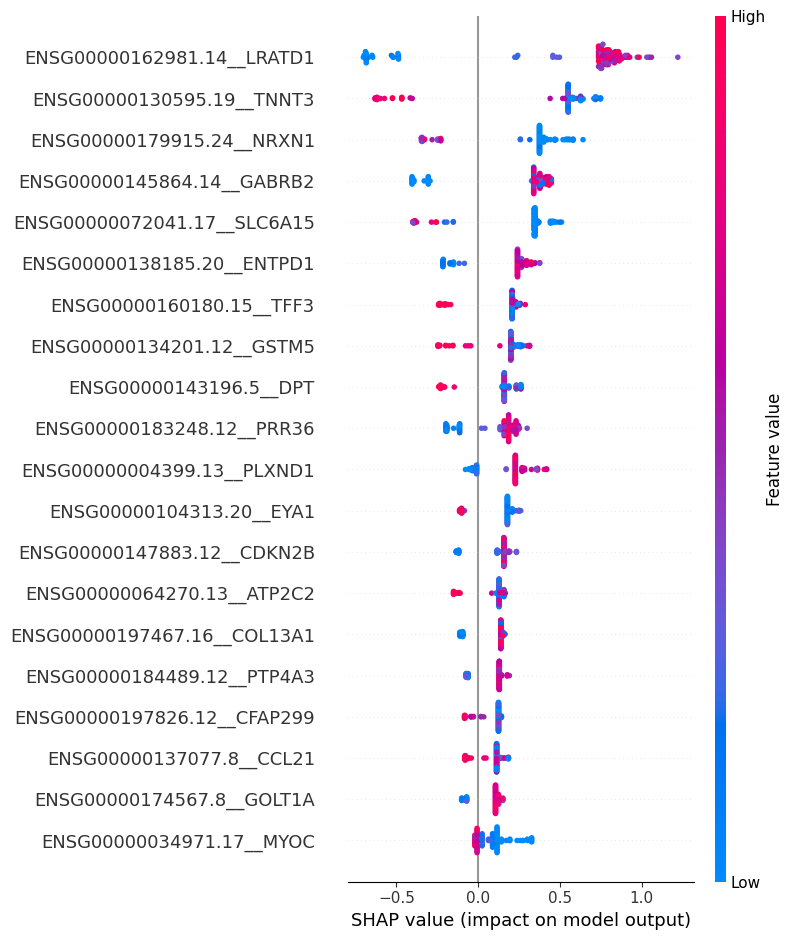

In [23]:

# ==========================================
# CELL 16: SHAP SUMMARY PLOT
# ==========================================

shap.summary_plot(
    shap_values,
    X_test_selected,
    max_display=20,
    show=False
)

plt.savefig(
    RESULTS_DIR / "04_SHAP_Summary_Plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


,Gene,Mean_Absolute_SHAP
283,ENSG00000162981.14__LRATD1,0.749323
143,ENSG00000130595.19__TNNT3,0.578644
389,ENSG00000179915.24__NRXN1,0.383707
202,ENSG00000145864.14__GABRB2,0.374605
33,ENSG00000072041.17__SLC6A15,0.357878
172,ENSG00000138185.20__ENTPD1,0.247438
266,ENSG00000160180.15__TFF3,0.216769
157,ENSG00000134201.12__GSTM5,0.210168
190,ENSG00000143196.5__DPT,0.186173
396,ENSG00000183248.12__PRR36,0.185860


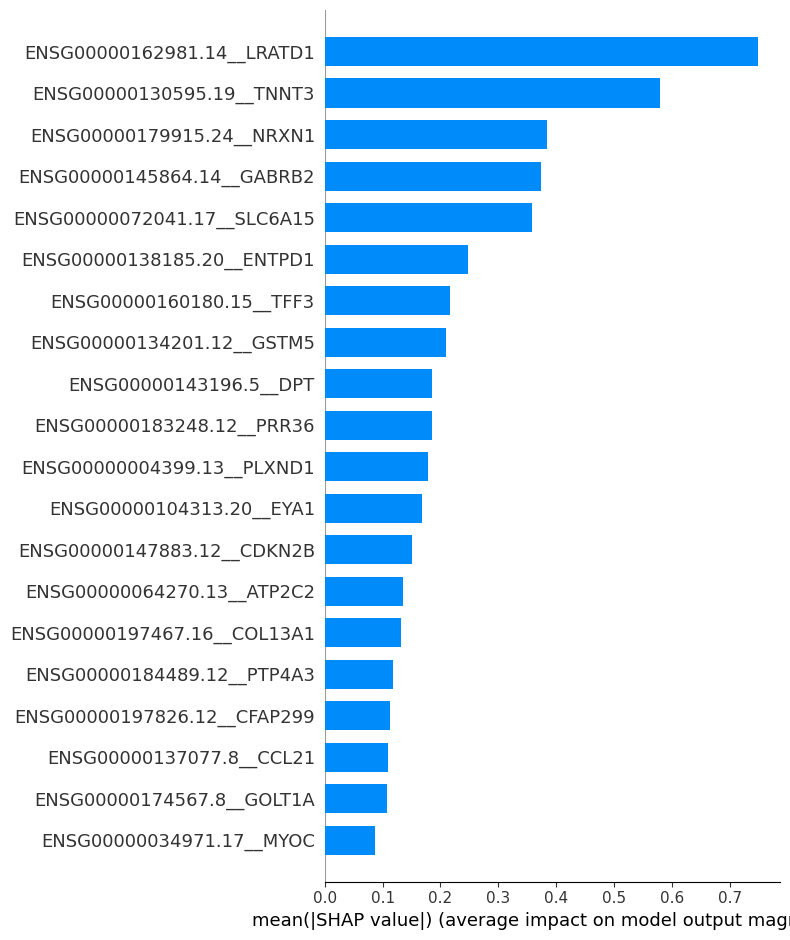

In [24]:

# ==========================================
# CELL 17: SHAP FEATURE IMPORTANCE
# ==========================================

shap_importance = pd.DataFrame({

    "Gene": selected_gene_names,

    "Mean_Absolute_SHAP": np.abs(
        shap_values
    ).mean(axis=0)

})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

display(
    shap_importance.head(20)
)

shap_importance.to_csv(
    RESULTS_DIR / "SHAP_Gene_Importance.csv",
    index=False
)

# Bar plot
shap.summary_plot(
    shap_values,
    X_test_selected,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.savefig(
    RESULTS_DIR / "05_SHAP_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Most important gene: ENSG00000162981.14__LRATD1


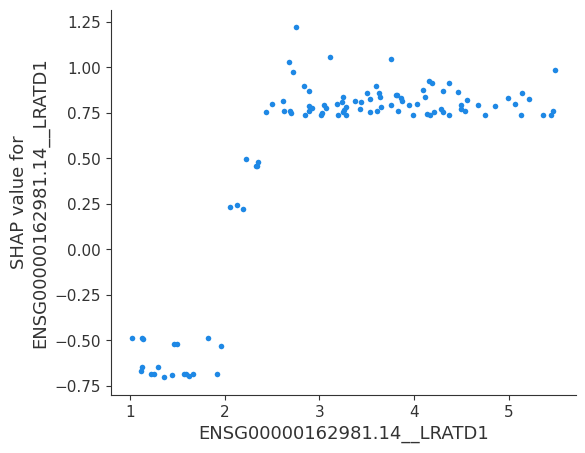

In [25]:

# ==========================================
# CELL 18: SHAP DEPENDENCE PLOT
# ==========================================

top_gene = shap_importance.iloc[0]["Gene"]

print("Most important gene:", top_gene)

shap.dependence_plot(
    top_gene,
    shap_values,
    X_test_selected,
    interaction_index=None,
    show=False
)

plt.savefig(
    RESULTS_DIR / "06_SHAP_Dependence_Plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


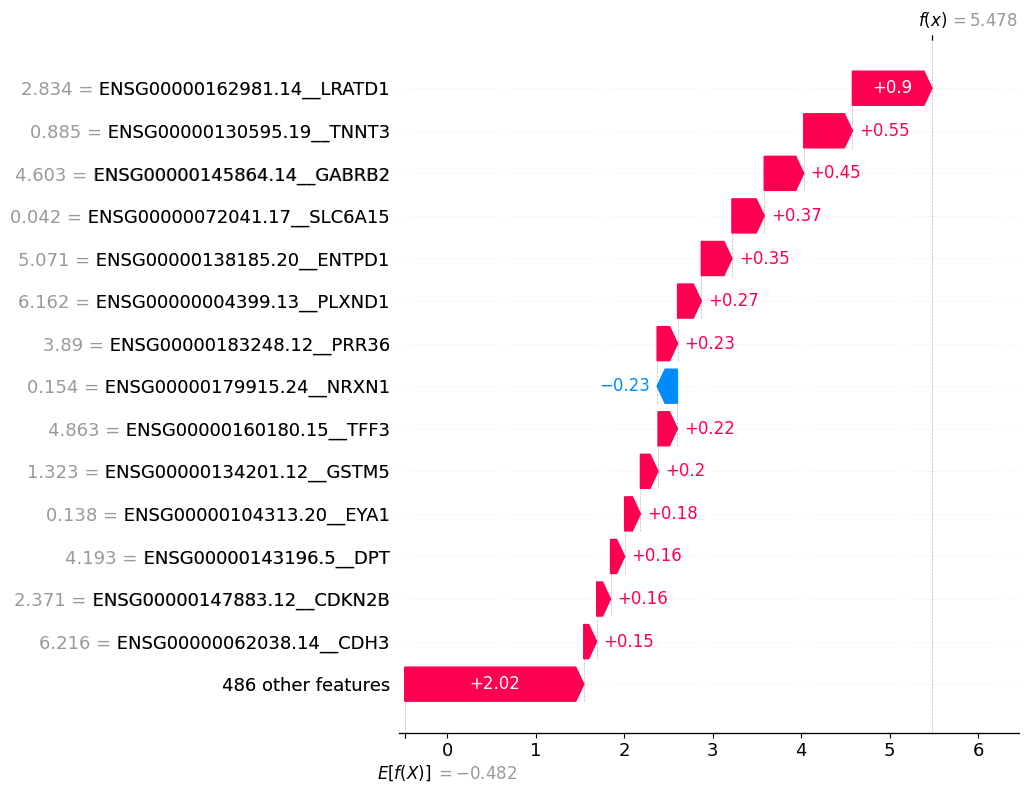

Explained held-out sample index: 0
Actual label: 1
Predicted label: 1


In [26]:
# ==========================================
# SHAP: INDIVIDUAL PATIENT EXPLANATION
# ==========================================

individual_index = 0

individual_explanation = shap_explanation[individual_index]

# Select the Tumor (class 1) explanation when SHAP returns
# a multi-output Explanation object.
if len(individual_explanation.shape) == 2:
    individual_explanation = individual_explanation[:, tumor_class_index]

shap.plots.waterfall(
    individual_explanation,
    max_display=15,
    show=False
)

plt.savefig(
    RESULTS_DIR / "07_SHAP_Waterfall_Plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Explained held-out sample index:", individual_index)
print("Actual label:", int(y_test.iloc[individual_index]))
print(
    "Predicted label:",
    int(shap_model.predict(X_test.iloc[[individual_index]])[0])
)

In [27]:
# ==========================================
# FINAL CELL: SAVE ALL SHAP AND MODEL OUTPUTS
# ==========================================

# Save class-1 SHAP values.
pd.DataFrame(
    shap_values,
    columns=selected_gene_names
).to_csv(
    RESULTS_DIR / "SHAP_Values.csv",
    index=False
)

# Save selected genes.
pd.DataFrame({
    "Selected_Gene": selected_gene_names
}).to_csv(
    RESULTS_DIR / "Selected_500_Genes.csv",
    index=False
)

# Save SHAP gene importance.
shap_importance.to_csv(
    RESULTS_DIR / "SHAP_Gene_Importance.csv",
    index=False
)

# Save the fitted model used for SHAP.
joblib.dump(
    shap_model,
    RESULTS_DIR / "SHAP_Explained_Fold1_Model.joblib"
)

# Save the final all-model comparison table again for convenience.
summary.to_csv(
    RESULTS_DIR / "All_Model_Performance_Summary.csv"
)

print("All research outputs saved successfully!")
print("\nResults directory:")
print(RESULTS_DIR)
print("\nFinal SHAP model:", best_tree_model)
print("Final SHAP feature count:", len(selected_gene_names))

All research outputs saved successfully!

Results directory:
/content/drive/MyDrive/datasets/TCGA_THCA_Research_Results

Final SHAP model: XGBoost
Final SHAP feature count: 500
